# Phát hiện gian lận thẻ tín dụng — Phân tích dữ liệu & Mô hình
**Tác giả:** Nguyễn Văn Tùng (PeterPark) · **Dữ liệu:** Credit Card Fraud Detection — Worldline & ULB Machine Learning Group (giấy phép ODbL).

Bộ dữ liệu gồm các giao dịch thẻ của chủ thẻ châu Âu trong **2 ngày (9/2013)**. Lưu ý trung thực về dữ liệu:
- `V1..V28` là các thành phần **PCA đã ẩn danh** → không biết ý nghĩa nghiệp vụ (không có merchant, quốc gia, thiết bị...).
- Chỉ `Time` (số giây kể từ giao dịch đầu tiên), `Amount` (số tiền, EUR) và `Class` (1 = gian lận) là diễn giải được.
- Giờ trong ngày được suy ra từ `Time` nên là **giờ tương đối** so với giao dịch đầu tiên.

In [1]:
import sqlite3, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_recall_curve, average_precision_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
RED, BLUE, GREY = '#E63946', '#1D3557', '#A8A8A8'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True); PBI = Path('powerbi'); PBI.mkdir(exist_ok=True)
df = pd.read_csv('data/creditcard.csv')
df.insert(0, 'id', np.arange(1, len(df)+1))
df['gio'] = ((df.Time // 3600) % 24).astype(int)
df['ngay'] = (df.Time // 86400).astype(int) + 1
BINS = [-0.01, 1, 5, 10, 25, 50, 100, 250, 500, 1000, 1e9]
LBL = ['0-1','1-5','5-10','10-25','25-50','50-100','100-250','250-500','500-1000','>1000']
df['khoang_tien'] = pd.cut(df.Amount, BINS, labels=LBL).astype(str)
df['khoang_tien_id'] = df.khoang_tien.map({l:i+1 for i,l in enumerate(LBL)})
print(df.shape); df[['Time','Amount','Class','gio','ngay']].describe().round(2)

(284807, 36)


,Time,Amount,Class,gio,ngay
count,284807.00,284807.00,284807.00,284807.00,284807.00
mean,94813.86,88.35,0.00,14.05,1.49
std,47488.15,250.12,0.04,5.84,0.50
min,0.00,0.00,0.00,0.00,1.00
25%,54201.50,5.60,0.00,10.00,1.00
50%,84692.00,22.00,0.00,15.00,1.00
75%,139320.50,77.16,0.00,19.00,2.00
max,172792.00,25691.16,1.00,23.00,2.00


## 1. Nạp vào SQLite và tổng quan

In [2]:
con = sqlite3.connect(':memory:'); df.to_sql('giao_dich', con, index=False)
def q(f): sql = Path('sql')/f; print(sql.read_text(encoding='utf-8').splitlines()[0]); return pd.read_sql(sql.read_text(encoding='utf-8'), con)
q('01_tong_quan.sql')

-- Q1. Tổng quan: số giao dịch, số gian lận, tỷ lệ, tổng tiền


,so_giao_dich,so_gian_lan,ty_le_gian_lan_pct,tong_tien,tien_gian_lan
0,284807,492,0.173,25162590.01,60127.97


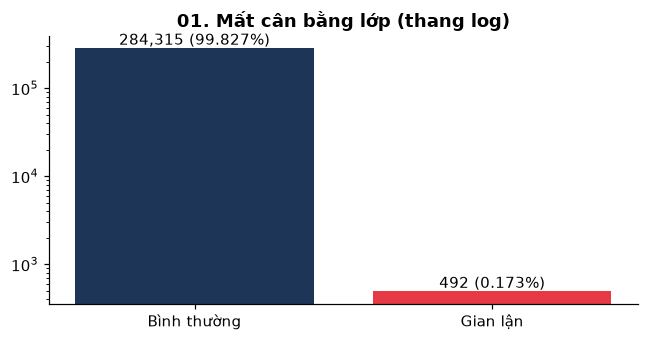

In [3]:
fig, ax = plt.subplots(figsize=(6,3.2)); vc = df.Class.value_counts()
ax.bar(['Bình thường','Gian lận'], vc.values, color=[BLUE,RED]); ax.set_yscale('log')
for i,v in enumerate(vc.values): ax.text(i, v, f'{v:,} ({v/len(df):.3%})', ha='center', va='bottom')
ax.set_title('01. Mất cân bằng lớp (thang log)'); plt.tight_layout(); plt.savefig(CHARTS/'01_mat_can_bang.png'); plt.show()

**Nhận xét:** gian lận chỉ chiếm phần rất nhỏ → *accuracy* vô nghĩa (đoán toàn bộ là 'bình thường' vẫn đạt >99.8%). Phải dùng precision, recall, PR-AUC.

## 2. Phân bố số tiền: gian lận vs bình thường

-- Q2. So sánh số tiền giao dịch gian lận và bình thường


,Class,so_gd,tb,nho_nhat,lon_nhat,so_gd_0_dong
0,0,284315,88.29,0.0,25691.16,1798
1,1,492,122.21,0.0,2125.87,27


Class
0    22.00
1     9.25
Name: trung_vi, dtype: float64


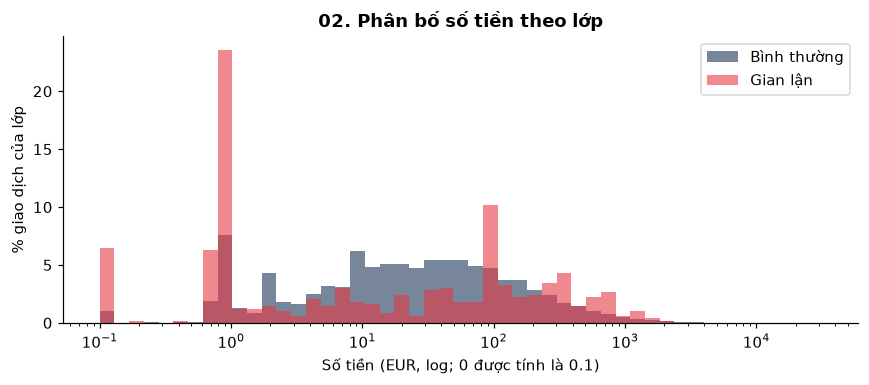

In [4]:
display(q('02_so_tien_theo_lop.sql'))
print(df.groupby('Class').Amount.median().rename('trung_vi'))
fig, ax = plt.subplots(figsize=(8,3.6)); b = np.logspace(-1, 4.5, 50)
for c,col,l in [(0,BLUE,'Bình thường'),(1,RED,'Gian lận')]:
    v=df.loc[df.Class==c,'Amount'].clip(lower=0.1); ax.hist(v, bins=b, weights=np.full(len(v),100/len(v)), alpha=.6, color=col, label=l)
ax.set_xscale('log'); ax.set_ylabel('% giao dịch của lớp'); ax.set_xlabel('Số tiền (EUR, log; 0 được tính là 0.1)'); ax.legend(); ax.set_title('02. Phân bố số tiền theo lớp')
plt.tight_layout(); plt.savefig(CHARTS/'02_phan_bo_so_tien.png'); plt.show()

-- Q4. Tỷ lệ gian lận theo khoảng số tiền


,khoang_tien,tu,so_gd,so_gian_lan,ty_le_pct,tien_gian_lan
0,0-1,0.00,30492,181,0.594,139.56
1,1-5,1.01,38540,41,0.106,111.37
2,5-10,5.01,31232,27,0.086,207.97
3,10-25,10.01,50090,27,0.054,467.21
4,25-50,25.01,40691,30,0.074,1147.82
5,50-100,50.01,37254,56,0.150,4945.33
6,100-250,100.01,33873,56,0.165,8662.14
7,250-500,250.07,13493,39,0.289,13251.67
8,500-1000,500.04,6202,26,0.419,17957.57
9,>1000,1000.10,2940,9,0.306,13237.33


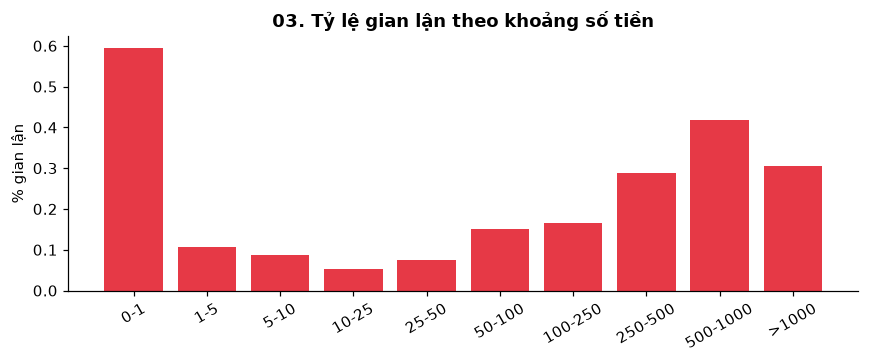

In [5]:
kt = q('04_khoang_tien.sql'); display(kt)
fig, ax = plt.subplots(figsize=(8,3.4)); ax.bar(kt.khoang_tien, kt.ty_le_pct, color=RED)
ax.set_ylabel('% gian lận'); ax.set_title('03. Tỷ lệ gian lận theo khoảng số tiền'); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig(CHARTS/'03_ty_le_theo_khoang_tien.png'); plt.show()

## 3. Giao dịch 'thăm dò' số tiền nhỏ (card testing)
Kẻ gian thường thử thẻ bằng giao dịch rất nhỏ trước khi rút lớn. Kiểm tra xem dữ liệu có ủng hộ giả thuyết này không.

In [6]:
td = q('05_giao_dich_tham_do.sql'); display(td)
print('Tỷ lệ gian lận chung: %.3f%%' % (100*df.Class.mean()))
print('Số tiền phổ biến nhất trong gian lận:'); print(df[df.Class==1].Amount.value_counts().head(5))

-- Q5. Giao dịch "thăm dò" số tiền rất nhỏ (≤ 1 và ≤ 2 đơn vị tiền)


,nhom,so_gd,so_gian_lan,ty_le_pct
0,≤1,30492,181,0.594
1,1-2,17589,18,0.102
2,>2,236726,293,0.124


Tỷ lệ gian lận chung: 0.173%
Số tiền phổ biến nhất trong gian lận:
Amount
1.00     113
0.00      27
99.99     27
0.76      17
0.77      10
Name: count, dtype: int64


## 4. Gian lận theo giờ và theo ngày

-- Q3. Tỷ lệ gian lận theo giờ (giờ tương đối tính từ giao dịch đầu tiên)


-- Q6. So sánh 2 ngày trong dữ liệu


,ngay,so_gd,so_gian_lan,ty_le_pct,tien_gian_lan
0,1,144786,281,0.194,33239.11
1,2,140021,211,0.151,26888.86


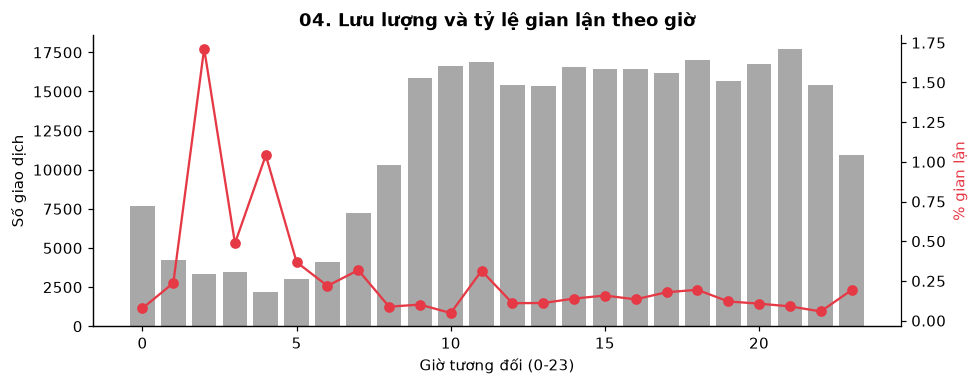

   gio  so_gd  so_gian_lan  ty_le_pct
2    2   3328           57      1.713
4    4   2209           23      1.041
3    3   3492           17      0.487
5    5   2990           11      0.368


In [7]:
g = q('03_theo_gio.sql'); display(q('06_theo_ngay.sql'))
fig, ax = plt.subplots(figsize=(9,3.6)); ax2 = ax.twinx()
ax.bar(g.gio, g.so_gd, color=GREY, label='Số giao dịch'); ax2.plot(g.gio, g.ty_le_pct, color=RED, marker='o', label='% gian lận')
ax.set_xlabel('Giờ tương đối (0-23)'); ax.set_ylabel('Số giao dịch'); ax2.set_ylabel('% gian lận', color=RED)
ax.set_title('04. Lưu lượng và tỷ lệ gian lận theo giờ'); ax2.spines['right'].set_visible(True)
plt.tight_layout(); plt.savefig(CHARTS/'04_theo_gio.png'); plt.show()
print(g.sort_values('ty_le_pct', ascending=False).head(4))

## 5. Gian lận có dồn cụm theo thời gian không?

-- Q7. Cửa sổ 10 phút có nhiều giao dịch gian lận nhất (gian lận có xu hướng dồn cụm?)


,cua_so_10p,tu_giay,so_gd,so_gian_lan
0,156,93600.0,426,23
1,68,40800.0,1447,23
2,69,41400.0,1406,10
3,128,76800.0,1641,9
4,14,8403.0,218,9
5,113,67800.0,1527,8
6,59,35400.0,1300,8
7,44,26400.0,549,8
8,12,7200.0,324,8
9,253,151800.0,1436,7


Số cửa sổ 10 phút: 288 | có gian lận: 180 | top 5% cửa sổ chứa 27.8% gian lận
Khoảng cách trung vị giữa 2 gian lận liên tiếp: 126 giây; 37.3% cặp cách nhau < 60 giây


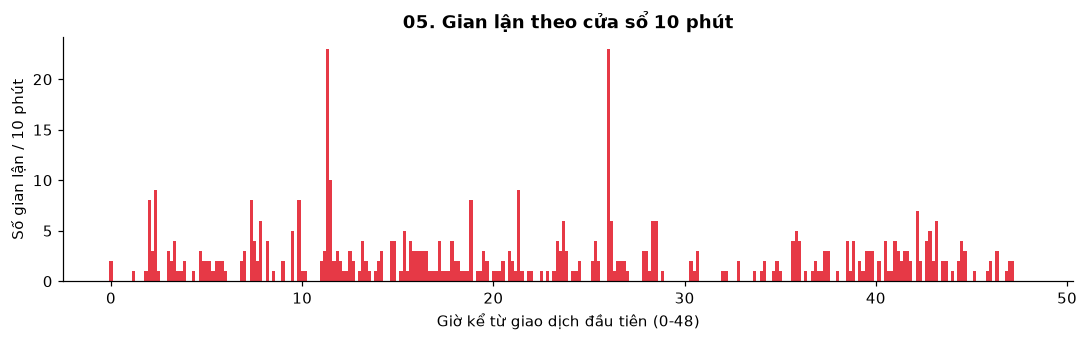

In [8]:
display(q('07_cum_thoi_gian.sql'))
w = df.groupby(df.Time//600).Class.sum()
print('Số cửa sổ 10 phút:', len(w), '| có gian lận:', (w>0).sum(), '| top 5%% cửa sổ chứa %.1f%% gian lận' % (100*w.sort_values(ascending=False).head(int(len(w)*.05)).sum()/w.sum()))
ft = np.sort(df.loc[df.Class==1,'Time'].values); gap = np.diff(ft)
print('Khoảng cách trung vị giữa 2 gian lận liên tiếp: %.0f giây; %.1f%% cặp cách nhau < 60 giây' % (np.median(gap), 100*(gap<60).mean()))
fig, ax = plt.subplots(figsize=(10,3.2)); ax.bar(w.index*600/3600, w.values, width=600/3600, color=RED)
ax.set_xlabel('Giờ kể từ giao dịch đầu tiên (0-48)'); ax.set_ylabel('Số gian lận / 10 phút'); ax.set_title('05. Gian lận theo cửa sổ 10 phút')
plt.tight_layout(); plt.savefig(CHARTS/'05_cum_thoi_gian.png'); plt.show()

## 6. Tiền mất vs số lượng giao dịch gian lận

-- Q8. Bao nhiêu % tiền gian lận nằm ở 10% giao dịch gian lận lớn nhất?


,decile,so_gd,tien,pct_tien
0,1,50,37286.10,62.0
1,2,50,12323.71,20.5
2,3,49,5398.71,9.0
3,4,49,3580.49,6.0
4,5,49,1118.37,1.9
5,6,49,259.17,0.4
6,7,49,55.86,0.1
7,8,49,49.00,0.1
8,9,49,44.84,0.1
9,10,49,11.72,0.0


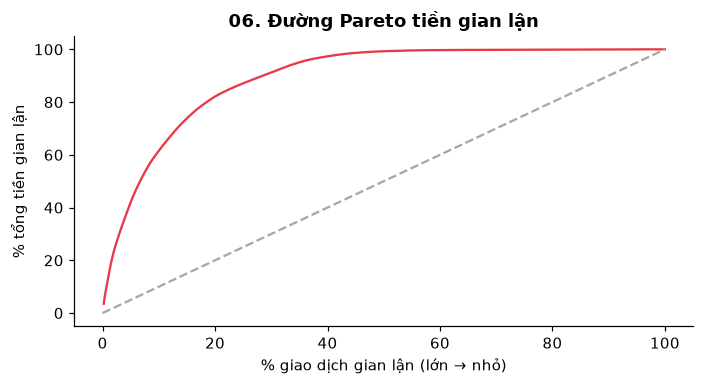

Top 10% gian lận lớn nhất = 62.0% tiền mất; 50.6% gian lận có số tiền ≤ 10 EUR
-- Q10. Giờ có số tiền gian lận cao nhất


,gio,so_gian_lan,tien_gian_lan
0,11,53,6570.73
1,18,33,6345.14
2,2,57,4517.98
3,16,22,4505.45
4,14,23,3641.12


-- Q9. Giao dịch trùng lặp hoàn toàn (cùng Time, Amount, V1..V28, Class)


,so_dong_trung
0,1081


In [9]:
dec = q('08_tien_mat_top.sql'); display(dec)
f = df[df.Class==1].Amount.sort_values(ascending=False).values; cum = f.cumsum()/f.sum()
fig, ax = plt.subplots(figsize=(6.5,3.6)); ax.plot(np.arange(1,len(f)+1)/len(f)*100, cum*100, color=RED)
ax.plot([0,100],[0,100],'--',color=GREY); ax.set_xlabel('% giao dịch gian lận (lớn → nhỏ)'); ax.set_ylabel('% tổng tiền gian lận')
ax.set_title('06. Đường Pareto tiền gian lận'); plt.tight_layout(); plt.savefig(CHARTS/'06_pareto_tien.png'); plt.show()
print('Top 10%% gian lận lớn nhất = %.1f%% tiền mất; %.1f%% gian lận có số tiền ≤ 10 EUR' % (dec.pct_tien[0], 100*(f<=10).mean()))
display(q('10_gio_tien_mat.sql')); display(q('09_trung_lap.sql'))

## 7. Đặc trưng PCA nào tách 2 lớp tốt nhất?
Dùng thống kê **Kolmogorov–Smirnov** (khoảng cách lớn nhất giữa 2 hàm phân phối tích lũy) — càng gần 1 càng tách tốt. Nhắc lại: không thể diễn giải nghiệp vụ của V-features.

,dac_trung,ks,tb_binh_thuong,tb_gian_lan
13,V14,0.8428,0.0121,-6.9717
9,V10,0.8043,0.0098,-5.6769
11,V12,0.7839,0.0108,-6.2594
3,V4,0.7664,-0.0079,4.5420
10,V11,0.7561,-0.0066,3.8002
16,V17,0.7452,0.0115,-6.6658
2,V3,0.7037,0.0122,-7.0333
15,V16,0.6865,0.0072,-4.1399
6,V7,0.6606,0.0096,-5.5687
1,V2,0.6332,-0.0063,3.6238


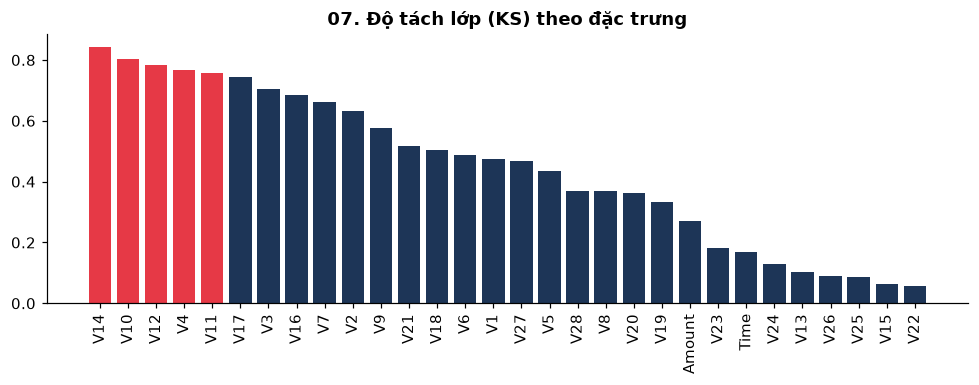

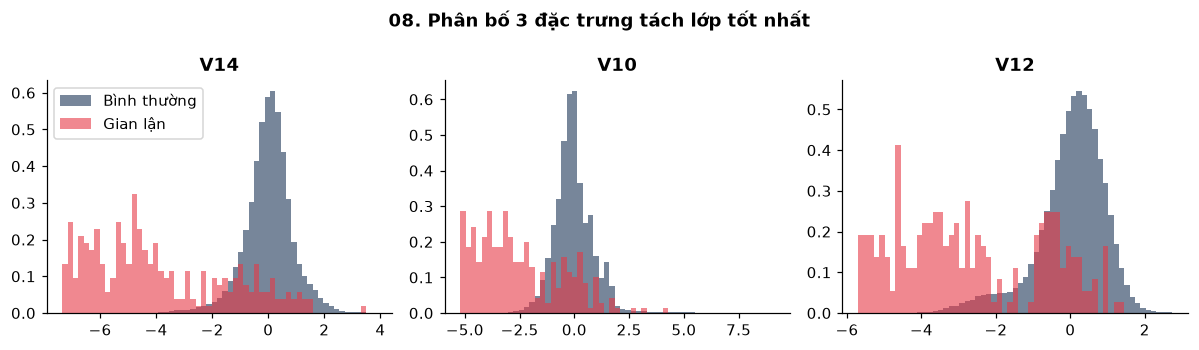

In [10]:
def ks(a, b):
    x = np.sort(np.concatenate([a,b])); return np.max(np.abs(np.searchsorted(np.sort(a), x, 'right')/len(a) - np.searchsorted(np.sort(b), x, 'right')/len(b)))
FEATS = [f'V{i}' for i in range(1,29)] + ['Amount','Time']
sep = pd.DataFrame({'dac_trung':FEATS, 'ks':[ks(df.loc[df.Class==0,c].values, df.loc[df.Class==1,c].values) for c in FEATS],
    'tb_binh_thuong':[df.loc[df.Class==0,c].mean() for c in FEATS], 'tb_gian_lan':[df.loc[df.Class==1,c].mean() for c in FEATS]}).sort_values('ks', ascending=False)
sep = sep.round(4); display(sep.head(10))
fig, ax = plt.subplots(figsize=(9,3.6)); ax.bar(sep.dac_trung, sep.ks, color=[RED if i<5 else BLUE for i in range(len(sep))])
ax.set_title('07. Độ tách lớp (KS) theo đặc trưng'); plt.xticks(rotation=90); plt.tight_layout(); plt.savefig(CHARTS/'07_ks_dac_trung.png'); plt.show()
top3 = sep.dac_trung.head(3).tolist()
fig, axs = plt.subplots(1,3, figsize=(11,3.2))
for a,c in zip(axs, top3):
    lo,hi = df[c].quantile([.001,.999]); b = np.linspace(lo,hi,60)
    a.hist(df.loc[df.Class==0,c], bins=b, density=True, alpha=.6, color=BLUE, label='Bình thường'); a.hist(df.loc[df.Class==1,c], bins=b, density=True, alpha=.6, color=RED, label='Gian lận'); a.set_title(c)
axs[0].legend(); fig.suptitle('08. Phân bố 3 đặc trưng tách lớp tốt nhất', fontweight='bold'); plt.tight_layout(); plt.savefig(CHARTS/'08_top3_phan_bo.png'); plt.show()

## 8. Mô hình: baseline luật vs Logistic Regression vs Random Forest
- **Chia theo thời gian** (70% đầu để huấn luyện, 30% cuối để kiểm tra) — mô phỏng thực tế: học quá khứ, dự đoán tương lai, tránh rò rỉ.
- **Mất cân bằng lớp:** dùng `class_weight` (không oversample tập kiểm tra), đánh giá bằng precision / recall / PR-AUC.
- **Baseline luật:** cờ đỏ khi đặc trưng tách tốt nhất vượt ngưỡng tìm trên tập train (kiểu luật analyst tự viết).

In [11]:
X = df[FEATS].copy(); X['Amount'] = np.log1p(X.Amount); X = X.drop(columns='Time'); X['gio'] = df.gio
y = df.Class.values; cut = int(len(df)*.7)
Xtr, Xte, ytr, yte = X.iloc[:cut], X.iloc[cut:], y[:cut], y[cut:]
print('Train: %d gd, %d gian lận | Test: %d gd, %d gian lận' % (len(ytr), ytr.sum(), len(yte), yte.sum()))
# Baseline luật: điểm = -(đặc trưng KS cao nhất) nếu gian lận có trung bình thấp hơn
f1 = sep.dac_trung.iloc[0]; sign = -1 if sep.tb_gian_lan.iloc[0] < sep.tb_binh_thuong.iloc[0] else 1
rule_tr = sign*Xtr[f1].values; rule_te = sign*Xte[f1].values
p,r,t = precision_recall_curve(ytr, rule_tr); fs = 2*p*r/(p+r+1e-12); thr_rule = t[np.argmax(fs[:-1])]
print(f'Luật: cờ đỏ khi {f1} {"<" if sign<0 else ">"} {sign*thr_rule:.3f}')
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=2000)).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample', n_jobs=-1, random_state=42).fit(Xtr, ytr)
S = {'Luật (1 đặc trưng)': rule_te, 'Logistic Regression': lr.predict_proba(Xte)[:,1], 'Random Forest': rf.predict_proba(Xte)[:,1]}

Train: 199364 gd, 384 gian lận | Test: 85443 gd, 108 gian lận
Luật: cờ đỏ khi V14 < -5.844


,mo_hinh,pr_auc,roc_auc,precision,recall,f1,so_canh_bao,accuracy_tham_khao
0,Luật (1 đặc trưng),0.6133,0.9435,0.6706,0.5278,0.5907,85,0.9991
1,Logistic Regression,0.7579,0.9798,0.0259,0.9074,0.0503,3787,0.9567
2,Random Forest,0.8247,0.9588,0.9877,0.7407,0.8466,81,0.9997


Accuracy nếu đoán toàn bộ bình thường: 0.9987  ← vì vậy không dùng accuracy


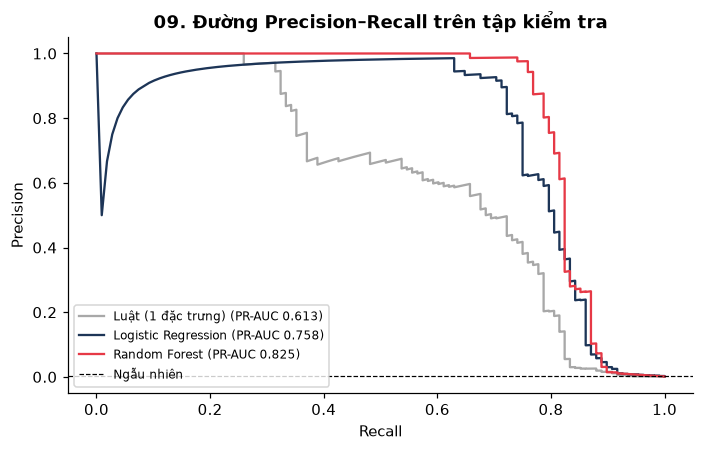

In [12]:
rows = []
for name, s in S.items():
    if name.startswith('Luật'): pred = (s >= thr_rule).astype(int)
    elif name.startswith('Logistic'): pred = (s >= 0.5).astype(int)
    else: pred = (s >= 0.5).astype(int)
    rows.append({'mo_hinh':name, 'pr_auc':average_precision_score(yte,s), 'roc_auc':roc_auc_score(yte,s), 'precision':precision_score(yte,pred),
                 'recall':recall_score(yte,pred), 'f1':f1_score(yte,pred), 'so_canh_bao':int(pred.sum()), 'accuracy_tham_khao':(pred==yte).mean()})
res = pd.DataFrame(rows).round(4); display(res)
print('Accuracy nếu đoán toàn bộ bình thường: %.4f  ← vì vậy không dùng accuracy' % (1-yte.mean()))
fig, ax = plt.subplots(figsize=(6.5,4.2))
for (name,s),col in zip(S.items(), [GREY,BLUE,RED]):
    p,r,_ = precision_recall_curve(yte,s); ax.plot(r,p,color=col,label=f'{name} (PR-AUC {average_precision_score(yte,s):.3f})')
ax.axhline(yte.mean(), ls='--', color='k', lw=.8, label='Ngẫu nhiên'); ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.legend(fontsize=8)
ax.set_title('09. Đường Precision–Recall trên tập kiểm tra'); plt.tight_layout(); plt.savefig(CHARTS/'09_pr_curve.png'); plt.show()

## 9. Lift / Gains: analyst phải xem bao nhiêu cảnh báo?
Sắp xếp giao dịch theo điểm rủi ro giảm dần; đếm số giao dịch phải xem để bắt được X% gian lận.

,mo_hinh,bat_50pct,bat_70pct,bat_80pct,bat_90pct
0,Luật (1 đặc trưng),81,154,426,6213
1,Logistic Regression,55,82,169,3238
2,Random Forest,54,77,115,6808


RF: xem top 0.1% (85 gd) bắt 75.9% gian lận; lift = 759x


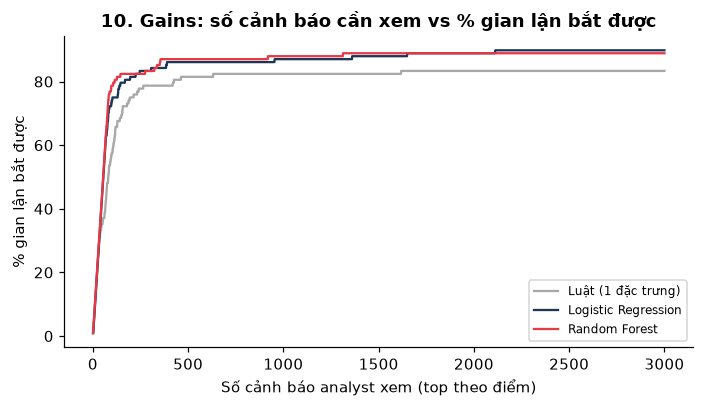

In [13]:
def alerts_needed(s, y, pct):
    o = np.argsort(-s); c = np.cumsum(y[o]); return int(np.searchsorted(c, np.ceil(pct*y.sum()))+1)
gains = pd.DataFrame([{'mo_hinh':n, **{f'bat_{int(p*100)}pct':alerts_needed(s,yte,p) for p in (.5,.7,.8,.9)}} for n,s in S.items()]); display(gains)
s = S['Random Forest']; o = np.argsort(-s); cum = np.cumsum(yte[o])/yte.sum(); k = np.arange(1,len(s)+1)
print('RF: xem top 0.1%% (%d gd) bắt %.1f%% gian lận; lift = %.0fx' % (int(len(s)*.001), 100*cum[int(len(s)*.001)-1], cum[int(len(s)*.001)-1]/.001))
fig, ax = plt.subplots(figsize=(6.5,3.8))
for (n,sc),col in zip(S.items(), [GREY,BLUE,RED]):
    oo = np.argsort(-sc); ax.plot(k[:3000], (np.cumsum(yte[oo])/yte.sum())[:3000]*100, color=col, label=n)
ax.set_xlabel('Số cảnh báo analyst xem (top theo điểm)'); ax.set_ylabel('% gian lận bắt được'); ax.legend(fontsize=8)
ax.set_title('10. Gains: số cảnh báo cần xem vs % gian lận bắt được'); plt.tight_layout(); plt.savefig(CHARTS/'10_gains.png'); plt.show()

## 10. Ngưỡng cảnh báo vs chi phí
**Giả định (có thể chỉnh):** mỗi cảnh báo analyst phải xem tốn `CHI_PHI_XEM = 5 EUR`; bỏ sót gian lận mất đúng số tiền giao dịch đó. Đây là giả định minh họa, không phải số liệu từ dataset.

Không có mô hình: mất 14566.58 EUR | Ngưỡng tối ưu 0.22: 97 cảnh báo, recall 78.7%, precision 87.6%, tổng chi phí 3021.48 EUR (giảm 79.3%)


,nguong,so_canh_bao,bat_duoc,bo_sot,precision,recall,chi_phi_xem,tien_bo_sot,tong_chi_phi
4,0.1,120,87,21,0.725,0.806,600.0,2534.71,3134.71
9,0.2,102,85,23,0.833,0.787,510.0,2536.48,3046.48
14,0.3,90,83,25,0.922,0.769,450.0,2775.96,3225.96
24,0.5,81,80,28,0.988,0.741,405.0,4097.58,4502.58
34,0.7,71,71,37,1.000,0.657,355.0,4742.80,5097.80
44,0.9,40,40,68,1.000,0.370,200.0,11952.97,12152.97


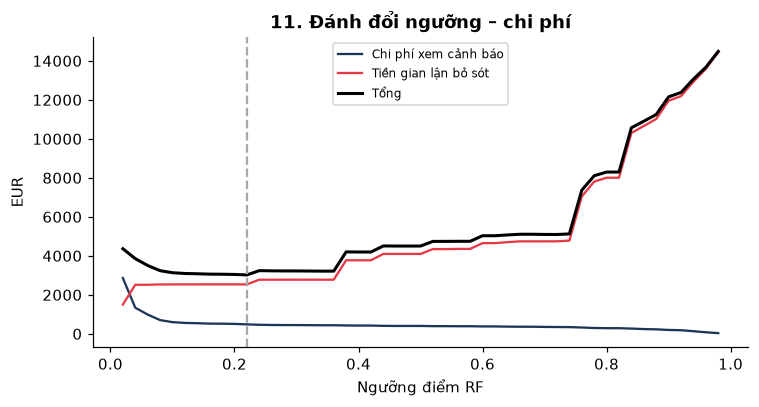

In [14]:
CHI_PHI_XEM = 5.0; amt = df.Amount.values[cut:]; s = S['Random Forest']
th = pd.DataFrame([{'nguong':t, 'so_canh_bao':int((s>=t).sum()), 'bat_duoc':int(yte[s>=t].sum()), 'bo_sot':int(yte[s<t].sum()),
    'precision':yte[s>=t].mean() if (s>=t).any() else np.nan, 'recall':yte[s>=t].sum()/yte.sum(),
    'chi_phi_xem':CHI_PHI_XEM*(s>=t).sum(), 'tien_bo_sot':amt[(s<t)&(yte==1)].sum()} for t in np.round(np.arange(0.02,1.0,0.02),2)])
th['tong_chi_phi'] = th.chi_phi_xem + th.tien_bo_sot; best = th.loc[th.tong_chi_phi.idxmin()]
base = amt[yte==1].sum()
print('Không có mô hình: mất %.2f EUR | Ngưỡng tối ưu %.2f: %d cảnh báo, recall %.1f%%, precision %.1f%%, tổng chi phí %.2f EUR (giảm %.1f%%)' % (base, best.nguong, best.so_canh_bao, 100*best.recall, 100*best.precision, best.tong_chi_phi, 100*(1-best.tong_chi_phi/base)))
display(th[th.nguong.isin([0.1,0.2,0.3,0.5,0.7,0.9])].round(3))
fig, ax = plt.subplots(figsize=(7,3.8)); ax.plot(th.nguong, th.chi_phi_xem, color=BLUE, label='Chi phí xem cảnh báo'); ax.plot(th.nguong, th.tien_bo_sot, color=RED, label='Tiền gian lận bỏ sót')
ax.plot(th.nguong, th.tong_chi_phi, color='k', lw=2, label='Tổng'); ax.axvline(best.nguong, ls='--', color=GREY); ax.set_xlabel('Ngưỡng điểm RF'); ax.set_ylabel('EUR'); ax.legend(fontsize=8)
ax.set_title('11. Đánh đổi ngưỡng – chi phí'); plt.tight_layout(); plt.savefig(CHARTS/'11_nguong_chi_phi.png'); plt.show()

## 11. Mức độ quan trọng của đặc trưng

,dac_trung,rf_importance,lr_he_so_abs
13,V14,0.1838,0.9375
9,V10,0.1301,0.8334
16,V17,0.1074,0.3562
3,V4,0.1028,1.4153
10,V11,0.0795,0.3739
11,V12,0.0672,1.1591
2,V3,0.0521,0.0391
15,V16,0.0392,0.5119
6,V7,0.0334,0.2624
1,V2,0.0294,0.2953


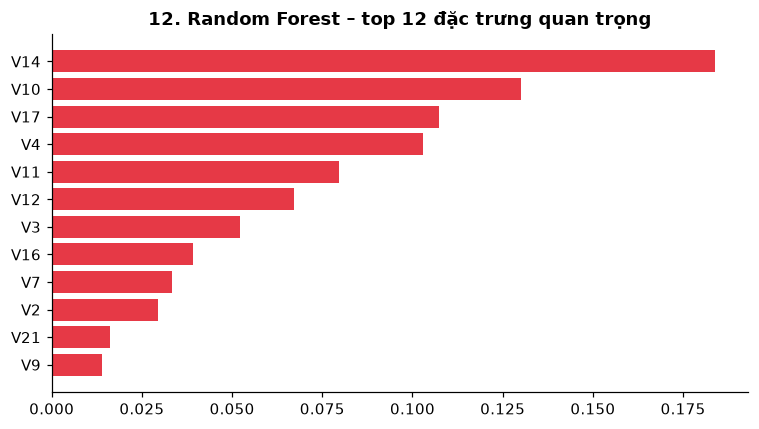

[[85323    12]
 [   23    85]]


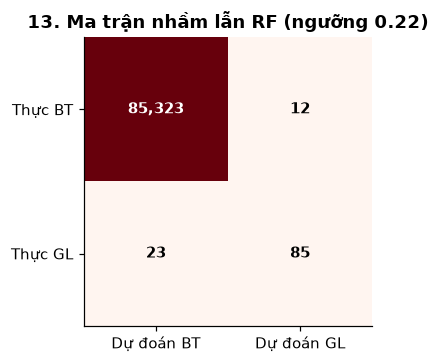

In [15]:
imp = pd.DataFrame({'dac_trung':Xtr.columns, 'rf_importance':rf.feature_importances_, 'lr_he_so_abs':np.abs(lr[-1].coef_[0])}).sort_values('rf_importance', ascending=False).round(4)
display(imp.head(10))
fig, ax = plt.subplots(figsize=(7,4)); t10 = imp.head(12)[::-1]; ax.barh(t10.dac_trung, t10.rf_importance, color=RED)
ax.set_title('12. Random Forest – top 12 đặc trưng quan trọng'); plt.tight_layout(); plt.savefig(CHARTS/'12_feature_importance.png'); plt.show()
cm = confusion_matrix(yte, (S['Random Forest']>=best.nguong).astype(int)); print(cm)
fig, ax = plt.subplots(figsize=(4,3.4)); ax.imshow(cm, cmap='Reds')
for i in range(2):
    for j in range(2): ax.text(j,i,f'{cm[i,j]:,}',ha='center',va='center',color='white' if cm[i,j]>1000 else 'k',fontweight='bold')
ax.set_xticks([0,1],['Dự đoán BT','Dự đoán GL']); ax.set_yticks([0,1],['Thực BT','Thực GL']); ax.set_title(f'13. Ma trận nhầm lẫn RF (ngưỡng {best.nguong:.2f})')
plt.tight_layout(); plt.savefig(CHARTS/'13_confusion_matrix.png'); plt.show()

## 12. Xuất dữ liệu cho Power BI

In [16]:
fact = df[['id','Time','ngay','gio','Amount','Class','khoang_tien_id'] + top3].rename(columns={'Time':'time_s','Amount':'so_tien','Class':'gian_lan'})
fact.round(5).to_csv(PBI/'fact_giao_dich.csv', index=False)
pd.DataFrame({'gio':range(24), 'nhan_gio':[f'{h:02d}h' for h in range(24)], 'buoi':['Đêm']*6+['Sáng']*6+['Chiều']*6+['Tối']*6}).to_csv(PBI/'dim_gio.csv', index=False)
pd.DataFrame({'khoang_tien_id':range(1,len(LBL)+1), 'khoang_tien':LBL, 'nhom':['Thăm dò (≤1)']+['Nhỏ']*3+['Vừa']*3+['Lớn']*3}).to_csv(PBI/'dim_khoang_tien.csv', index=False)
pred = pd.DataFrame({'id':df.id.values[cut:], 'diem_rf':S['Random Forest'].round(5), 'diem_lr':S['Logistic Regression'].round(5), 'thuc_te':yte})
pred['muc_rui_ro'] = pd.cut(pred.diem_rf, [-1,.1,.3,best.nguong if best.nguong>.3 else .5,1.01], labels=['1 Thấp','2 Trung bình','3 Cao','4 Rất cao']).astype(str)
pred['canh_bao'] = (pred.diem_rf>=best.nguong).astype(int); pred.to_csv(PBI/'fact_du_doan.csv', index=False)
print(pred.groupby('muc_rui_ro').agg(so_gd=('id','size'), gian_lan=('thuc_te','sum')))
th.round(4).to_csv(PBI/'tom_tat_nguong.csv', index=False); res.to_csv(PBI/'tom_tat_mo_hinh.csv', index=False)
sep.to_csv(PBI/'tom_tat_dac_trung.csv', index=False); gains.to_csv(PBI/'tom_tat_gains.csv', index=False)
df.groupby('Class').sample(frac=2000/len(df), random_state=42).sort_values('Time').drop(columns=['id']).to_csv('data/creditcard_sample_2k.csv', index=False)
for f in sorted(PBI.glob('*.csv')): print(f.name, f.stat().st_size//1024, 'KB')

              so_gd  gian_lan
muc_rui_ro                   
1 Thấp        85323        21
2 Trung bình     30         4
3 Cao             9         3
4 Rất cao        81        80
dim_gio.csv 0 KB
dim_khoang_tien.csv 0 KB
fact_du_doan.csv 2702 KB
fact_giao_dich.csv 15146 KB
tom_tat_dac_trung.csv 0 KB
tom_tat_gains.csv 0 KB
tom_tat_mo_hinh.csv 0 KB
tom_tat_nguong.csv 2 KB


## 13. Kết luận & khuyến nghị
Xem bảng insight trong README (mọi con số lấy từ output các ô trên).

**Hạn chế:** chỉ 2 ngày dữ liệu; V1..V28 là PCA ẩn danh nên không diễn giải được nghiệp vụ; giờ là giờ tương đối; chi phí xem cảnh báo là giả định; có các dòng trùng lặp được giữ nguyên như bản gốc.

*Credit: Worldline & Machine Learning Group, Université Libre de Bruxelles (ULB) — dữ liệu ODbL.*